In [360]:
import pandas as pd
import numpy as np
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import root_mean_squared_error
import matplotlib.pyplot as plt 
import seaborn as sns
import pmdarima as pm
sns.set_style('darkgrid')

In [361]:
df = pd.read_csv(r"C:\Users\volga\Desktop\taxi_forecasting\taxi_weather_clean_daily.csv", parse_dates=["date"])
df = df.sort_values("date").set_index("date")
df.index = pd.DatetimeIndex(df.index, freq="D")
display(df)

,day,month,year,day_of_week,day_of_year,pickup_count,sndp,temp,wdsp,prcp
date,,,,,,,,,,
2016-01-01 00:00:00+00:00,1,1,2016,6,1,345036,0.0,40.4,6.5,0.03
2016-01-02 00:00:00+00:00,2,1,2016,7,2,312830,0.0,35.8,6.0,0.00
2016-01-03 00:00:00+00:00,3,1,2016,1,3,302878,0.0,38.4,6.4,0.00
2016-01-04 00:00:00+00:00,4,1,2016,2,4,316008,0.0,30.8,7.0,0.00
2016-01-05 00:00:00+00:00,5,1,2016,3,5,343128,0.0,18.4,6.2,0.00
...,...,...,...,...,...,...,...,...,...,...
2019-12-27 00:00:00+00:00,27,12,2019,6,361,169618,0.0,49.4,4.7,0.00
2019-12-28 00:00:00+00:00,28,12,2019,7,362,172030,0.0,48.0,3.8,0.00
2019-12-29 00:00:00+00:00,29,12,2019,1,363,165128,0.0,42.6,3.1,0.00


## 1. Box-Jenkins Method
### 1.1 Identification

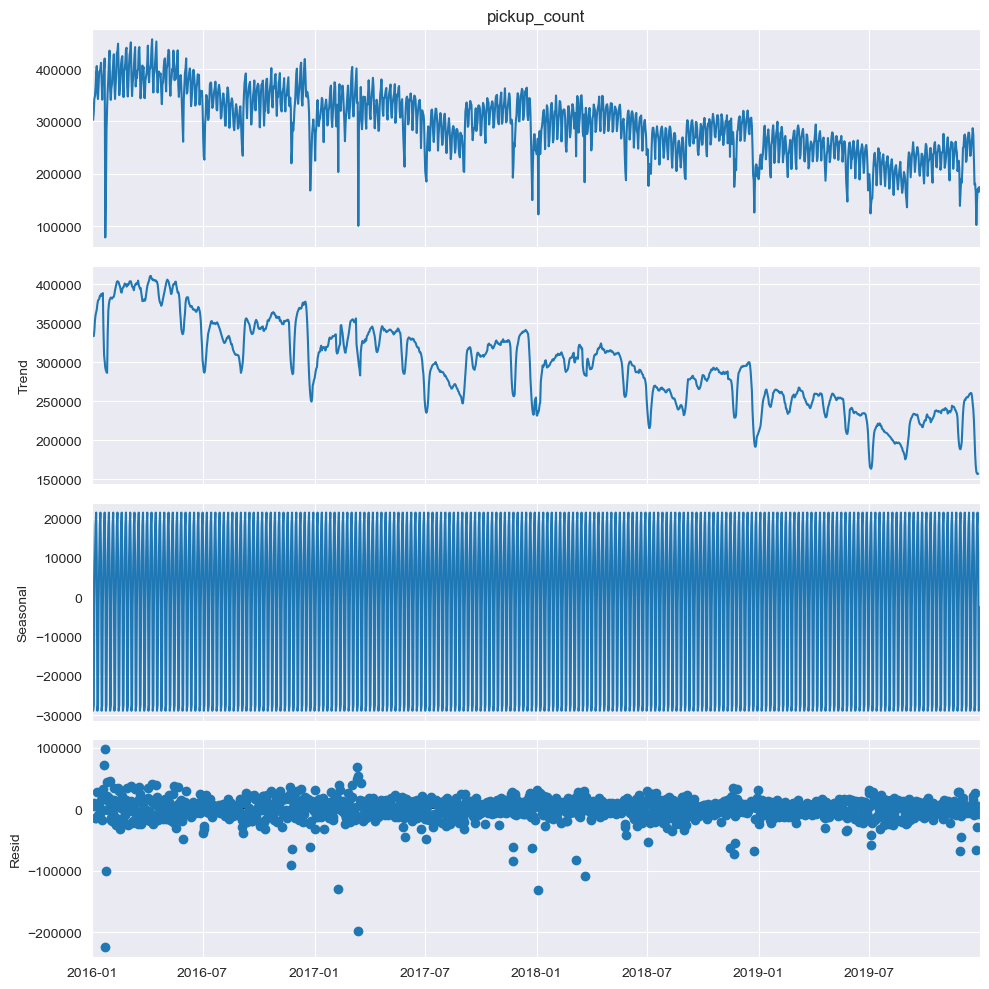

In [362]:
# Decompose data
decomp_results = seasonal_decompose(df['pickup_count'], period=7)

# Plot decomposed data
plt.rcParams["figure.figsize"] = (10,10)
decomp_results.plot()
plt.show()

#### Stationnarity Check

In [363]:
# Run Dicky-Fuller test
result = adfuller(df['pickup_count'])

print("The p-value:",result[1])

The p-value: 0.4712621148724432


because the p-value is not under 0.05, we can not reject the null hypothesis saying that the time series is non-stationnary. To make it stationnary, we will compute the first difference.

#### Differenciation to obtain stationnary series

The p-value: 6.416615853264893e-22


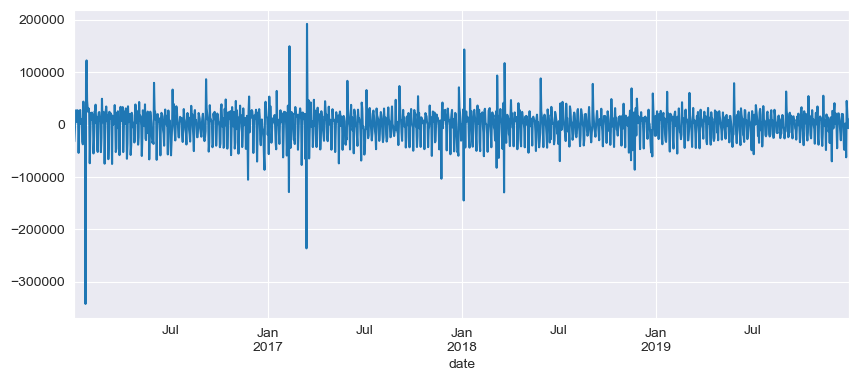

In [364]:
pickup_count_diff = df['pickup_count'].diff()
pickup_count_diff = pickup_count_diff.dropna()
plt.rcParams["figure.figsize"] = (10,4)
pickup_count_diff.plot()

# Run Dicky-Fuller test
result_diff = adfuller(pickup_count_diff)

print("The p-value:",result_diff[1])

now the p-value is under 0.05 and we can reject the null hypothesis and the data can be assumed that it is stationary

#### ACF and PACF Analysis

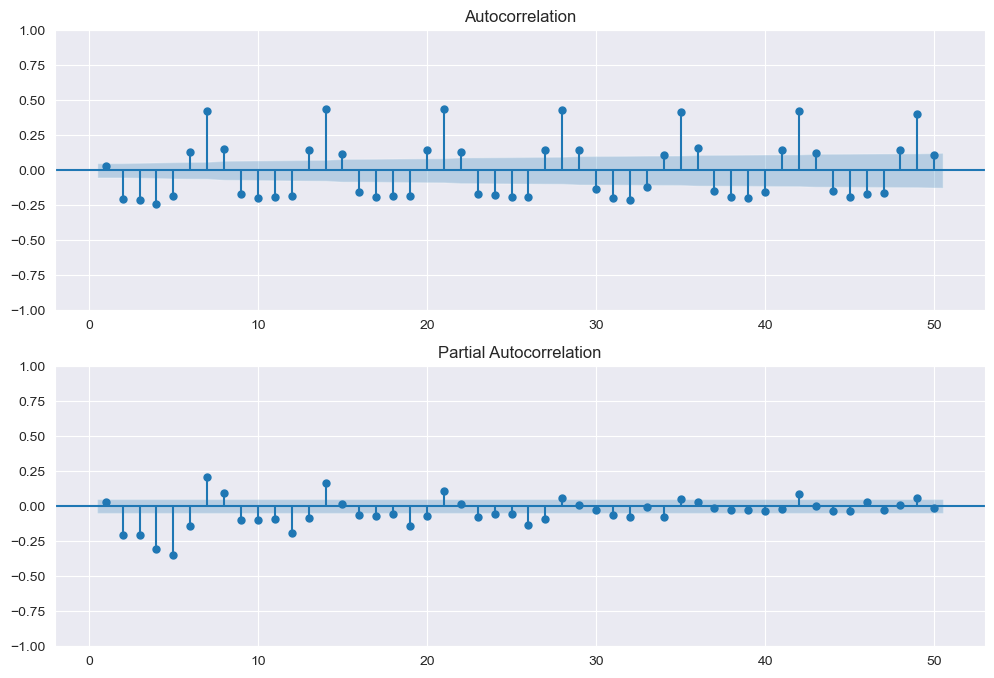

In [365]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, (ax1, ax2) = plt.subplots(2,1, figsize=(12,8))

plot_acf(pickup_count_diff, lags=50, zero=False, ax=ax1)

plot_pacf(pickup_count_diff, lags=50, zero=False, ax=ax2)

plt.show()

The ACF shows a periodic, almost sinusoidal pattern, suggesting a 7-day seasonality, while the PACF decays gradually without a clear cut-off, suggesting an ARMA model. Since the ADF test indicates that the series is non-stationary, differencing is required. These observations suggest using a SARIMA model to account for both non-stationarity and weekly seasonality.

## 2. Estimation and testing

In [366]:
# feature engineering 
# cyclical encoding for day of year
day_of_year = df["day_of_year"]
days_in_year = np.where(df.index.is_leap_year, 366, 365)

df["sin_year"] = np.sin(
    2 * np.pi * (day_of_year - 1) / days_in_year
)

In [367]:
# split of dataset in train/validation/test set
train_ratio = 0.70
validation_ratio = 0.15

n_observations = len(df)

train_end = int(n_observations * train_ratio)
validation_end = int(n_observations * (train_ratio + validation_ratio))

df_train = df.iloc[:train_end]                       # 70% 
df_validation = df.iloc[train_end:validation_end]    # 15% 
df_test = df.iloc[validation_end:]                   # 15% 

# number of split in validation/test set without overlapping
n_splits =  int((len(df)*0.15)//7 - 1)
tscv = TimeSeriesSplit(n_splits=n_splits, test_size=7)

### 2.1 Parameter estimation using AIC and BIC

In [368]:
y = df_train["pickup_count"]

# Selecting best model using AIC
model_aic = pm.auto_arima(
    y,
    seasonal=True,
    m=7,
    information_criterion="aic",
    stepwise=True,
    trace=True,
    error_action="ignore",
    suppress_warnings=True
)

# Selecting best model using BIC
model_bic = pm.auto_arima(
    y,
    seasonal=True,
    m=7,
    information_criterion="bic",
    stepwise=True,
    trace=True,
    error_action="ignore",
    suppress_warnings=True
)

print("\n Best model following AIC")
print(model_aic.summary())

print("\n Best model following BIC")
print(model_bic.summary())

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[7] intercept   : AIC=inf, Time=2.91 sec
 ARIMA(0,1,0)(0,0,0)[7] intercept   : AIC=24131.311, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[7] intercept   : AIC=23973.149, Time=0.17 sec
 ARIMA(0,1,1)(0,0,1)[7] intercept   : AIC=24030.039, Time=0.20 sec
 ARIMA(0,1,0)(0,0,0)[7]             : AIC=24129.312, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[7] intercept   : AIC=24133.288, Time=0.04 sec
 ARIMA(1,1,0)(2,0,0)[7] intercept   : AIC=23893.778, Time=1.17 sec
 ARIMA(1,1,0)(2,0,1)[7] intercept   : AIC=inf, Time=0.97 sec
 ARIMA(1,1,0)(1,0,1)[7] intercept   : AIC=inf, Time=0.89 sec
 ARIMA(0,1,0)(2,0,0)[7] intercept   : AIC=23910.756, Time=0.38 sec
 ARIMA(2,1,0)(2,0,0)[7] intercept   : AIC=23874.609, Time=1.45 sec
 ARIMA(2,1,0)(1,0,0)[7] intercept   : AIC=23953.503, Time=0.42 sec
 ARIMA(2,1,0)(2,0,1)[7] intercept   : AIC=inf, Time=1.29 sec
 ARIMA(2,1,0)(1,0,1)[7] intercept   : AIC=inf, Time=0.81 sec
 ARIMA(3,1,0)(2,0,0)[7] intercept   : AIC=23860.0

Both AIC and BIC select the same SARIMA configuration, with non-seasonal parameters (5, 1, 0) and seasonal parameters (2, 0, 1, 7).

### 2.2 Exogenous variable selection
The following code performs a rolling-window evaluation on the validation set to identify the best combination of exogenous variables. The mean RMSE is used as the criterion for forward feature selection.

In [369]:
def one_fold_validation(
    data_train,
    data_test,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    exog_cols=None,
    forecast_steps=7
):
    # exogenous variable 
    exog_train = data_train[exog_cols] if exog_cols else None
    exog_test = data_test[exog_cols] if exog_cols else None

    model = SARIMAX(
        data_train['pickup_count'],
        exog=exog_train,
        order=order,
        seasonal_order=seasonal_order
    )

    results = model.fit()
    
    # model prediction
    forecast = results.forecast(
        steps=forecast_steps,
        exog=exog_test
    )

    forecast_origin = data_train.index[-1]
    forecast_values = np.asarray(forecast)
    
    # rmse evaluation
    y_true = data_test['pickup_count'].iloc[:forecast_steps]
    RMSE = root_mean_squared_error(y_true, forecast)

    predictions = pd.DataFrame({
        "forecast_origin": forecast_origin,
        "date": data_test.index,
        "y_true": np.asarray(y_true),
        "y_pred": forecast_values
    })

    return predictions, RMSE


In [370]:
def evaluate_arimax_cv(
    df_train,
    df_validation,
    tscv,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    exog_variables=None,
    forecast_steps=7
):
    rmse_scores = []
    all_predictions = []

    for i, (train_index, test_index) in enumerate(tscv.split(df_validation)):

        df_train_fold = pd.concat([df_train, df_validation.iloc[train_index]])
        df_test_fold = df_validation.iloc[test_index]

        predictions, rmse = one_fold_validation(
            data_train=df_train_fold,
            data_test=df_test_fold,
            order=order,
            seasonal_order=seasonal_order,
            exog_cols=exog_variables,
            forecast_steps=forecast_steps
        )

        #print("Fold {} RMSE: {:.4f}".format(i, rmse))
        rmse_scores.append(rmse)
        all_predictions.append(predictions)

    predictions_df = pd.concat(all_predictions)

    rmse_mean = np.mean(rmse_scores)
    rmse_std = np.std(rmse_scores) 

    return predictions_df, rmse_mean, rmse_std


In [371]:
def forward_selection_sarimax(
    df_train,
    df_validation,
    tscv,
    candidate_exog,
    order=(5, 1, 0),
    seasonal_order=(2, 0, [1], 7),
    forecast_steps=7
):
    selected = []
    remaining = list(candidate_exog)
    history = []

    # Baseline without exogenous varibles 
    _, best_rmse, best_std = evaluate_arimax_cv(
        df_train=df_train,
        df_validation=df_validation,
        tscv=tscv,
        order=order,
        seasonal_order=seasonal_order,
        exog_variables=None,
        forecast_steps=forecast_steps
    )

    print(f"Baseline without exogenous feature : RMSE = {best_rmse:.4f}")

    history.append({
        "variables": [],
        "variable_ajoutee": None,
        "rmse_mean": best_rmse,
        "rmse_std": best_std
    })

    while remaining:
        candidates_results = []

        # testing remaining exogenous variable
        for variable in remaining:
            trial_variables = selected + [variable]

            _, rmse, std = evaluate_arimax_cv(
                df_train=df_train,
                df_validation=df_validation,
                tscv=tscv,
                order=order,
                seasonal_order=seasonal_order,
                exog_variables=trial_variables,
                forecast_steps=forecast_steps
            )

            candidates_results.append({
                "variable": variable,
                "variables": trial_variables,
                "rmse_mean": rmse,
                "rmse_std": std
            })

            print(
                f"Test {trial_variables} : "
                f"RMSE = {rmse:.4f}"
            )

        candidates_results = pd.DataFrame(candidates_results)

        # taking candidate result with best score
        candidates_results = candidates_results.sort_values(by="rmse_mean", ascending=True)

        winner = candidates_results.iloc[0]

        improvement = best_rmse - winner["rmse_mean"]

        # If no features improve the score -> stop the forward selection
        if improvement <= 0:
            print("no exogenes variables allow an improvement")
            break

        selected.append(winner["variable"])
        remaining.remove(winner["variable"])

        best_rmse = winner["rmse_mean"]
        best_std = winner["rmse_std"]

        history.append({
            "variables": selected.copy(),
            "variable_ajoutee": winner["variable"],
            "rmse_mean": best_rmse,
            "rmse_std": best_std
        })
        
    history_df = pd.DataFrame(history)

    return selected, history_df


In [372]:
selected_exog, history = forward_selection_sarimax(
    df_train=df_train,
    df_validation=df_validation,
    tscv=tscv,
    candidate_exog=["wdsp", "temp", "prcp", "sndp", "sin_year", "day_of_year", "day"],
    order=(5, 1, 0),
    seasonal_order=(2, 0, [1], 7),
    forecast_steps=7
)

print("Best set of features :", selected_exog)
display(history)

Baseline without exogenous feature : RMSE = 21205.5226
Test ['wdsp'] : RMSE = 21367.9844
Test ['temp'] : RMSE = 21131.4340
Test ['prcp'] : RMSE = 21305.7619
Test ['sndp'] : RMSE = 21149.8238
Test ['sin_year'] : RMSE = 21296.7596
Test ['day_of_year'] : RMSE = 21291.7022
Test ['day'] : RMSE = 21199.4882
Test ['temp', 'wdsp'] : RMSE = 21251.2057
Test ['temp', 'prcp'] : RMSE = 21249.5025
Test ['temp', 'sndp'] : RMSE = 21095.0815
Test ['temp', 'sin_year'] : RMSE = 21213.8380
Test ['temp', 'day_of_year'] : RMSE = 21217.1776
Test ['temp', 'day'] : RMSE = 21112.9612
Test ['temp', 'sndp', 'wdsp'] : RMSE = 21140.1269
Test ['temp', 'sndp', 'prcp'] : RMSE = 21179.8288
Test ['temp', 'sndp', 'sin_year'] : RMSE = 21187.0134
Test ['temp', 'sndp', 'day_of_year'] : RMSE = 21174.0700
Test ['temp', 'sndp', 'day'] : RMSE = 21052.4654
Test ['temp', 'sndp', 'day', 'wdsp'] : RMSE = 21097.0912
Test ['temp', 'sndp', 'day', 'prcp'] : RMSE = 21135.9162
Test ['temp', 'sndp', 'day', 'sin_year'] : RMSE = 21144.7494


,variables,variable_ajoutee,rmse_mean,rmse_std
0,[],None,21205.522636,18269.916192
1,[temp],temp,21131.433959,18453.473222
2,"[temp, sndp]",sndp,21095.081509,17591.235244
3,"[temp, sndp, day]",day,21052.465437,17568.393882


#### Interpretation
The exogenous features do not seem to improve significantly the model's predictions. Moreover, the sinusoidal feature representing the time of year does not improve the score either. This suggests that the model struggles to capture yearly seasonal patterns, which is problematic because taxi demand tends to decrease during certain periods of the year, such as around New Year.

The model already uses a seasonal period of 7 to capture weekly seasonality. However, the SARIMAX seasonal period parameter cannot directly capture two different seasonal patterns at the same time. Setting the seasonal period to 365 to capture yearly seasonality is not an ideal solution, as it would significantly increase the model's computational cost.

#### Using a Lag Feature to Capture Yearly Seasonality

In [373]:
# create lag 365 feature
df["pickup_count_lag_365"] = df["pickup_count"].shift(365)

df_train_lag365 = df.iloc[:train_end]
df_validation_lag365 = df.iloc[train_end:validation_end]
df_test_lag365 = df.iloc[validation_end:]


df_train_lag365 = df_train_lag365.dropna(subset=["pickup_count_lag_365"]).copy()


In [374]:
# Rolling window evaluation of SARIMAX with lag365
_, rmse_mean_run1, rmse_std_run1 = evaluate_arimax_cv(
    df_train=df_train_lag365,
    df_validation=df_validation_lag365,
    tscv=tscv,
    order=order,
    seasonal_order=seasonal_order,
    exog_variables=["pickup_count_lag_365"],
    forecast_steps=forecast_steps
)

# Rolling window evaluation of SARIMA without lag365
_, rmse_mean_run2, rmse_std_run2 = evaluate_arimax_cv(
    df_train=df_train_lag365,
    df_validation=df_validation_lag365,
    tscv=tscv,
    order=order,
    seasonal_order=seasonal_order,
    exog_variables=None,
    forecast_steps=forecast_steps
)


results = pd.DataFrame({
    "Run": [
        "1 - SARIMAX with lag365 feature",
        "2 - SARIMA without lag365 feature"
    ],
    "RMSE mean": [
        rmse_mean_run1,
        rmse_mean_run2
    ],
    "RMSE std": [
        rmse_std_run1,
        rmse_std_run2
    ]
})
print(results.to_string(index=False))


                              Run   RMSE mean     RMSE std
  1 - SARIMAX with lag365 feature 19947.25469 14665.220403
2 - SARIMA without lag365 feature 21829.07023 18395.337878


Our rolling-window validation shows that SARIMAX with lag365 outperforms the model using weather features. Since lag365 requires removing the first year of data, we also compared it with a SARIMA model trained on the same reduced dataset to isolate the effect of the lag feature.

Including lag365 reduced the mean RMSE by 8.6% and its standard deviation by 20.3%, suggesting that yearly seasonality improves both prediction accuracy and consistency. One possible explanation is that accounting for yearly seasonality helps the model better anticipate days with unusually high or low taxi demand, thereby reducing the occurrence of large errors.

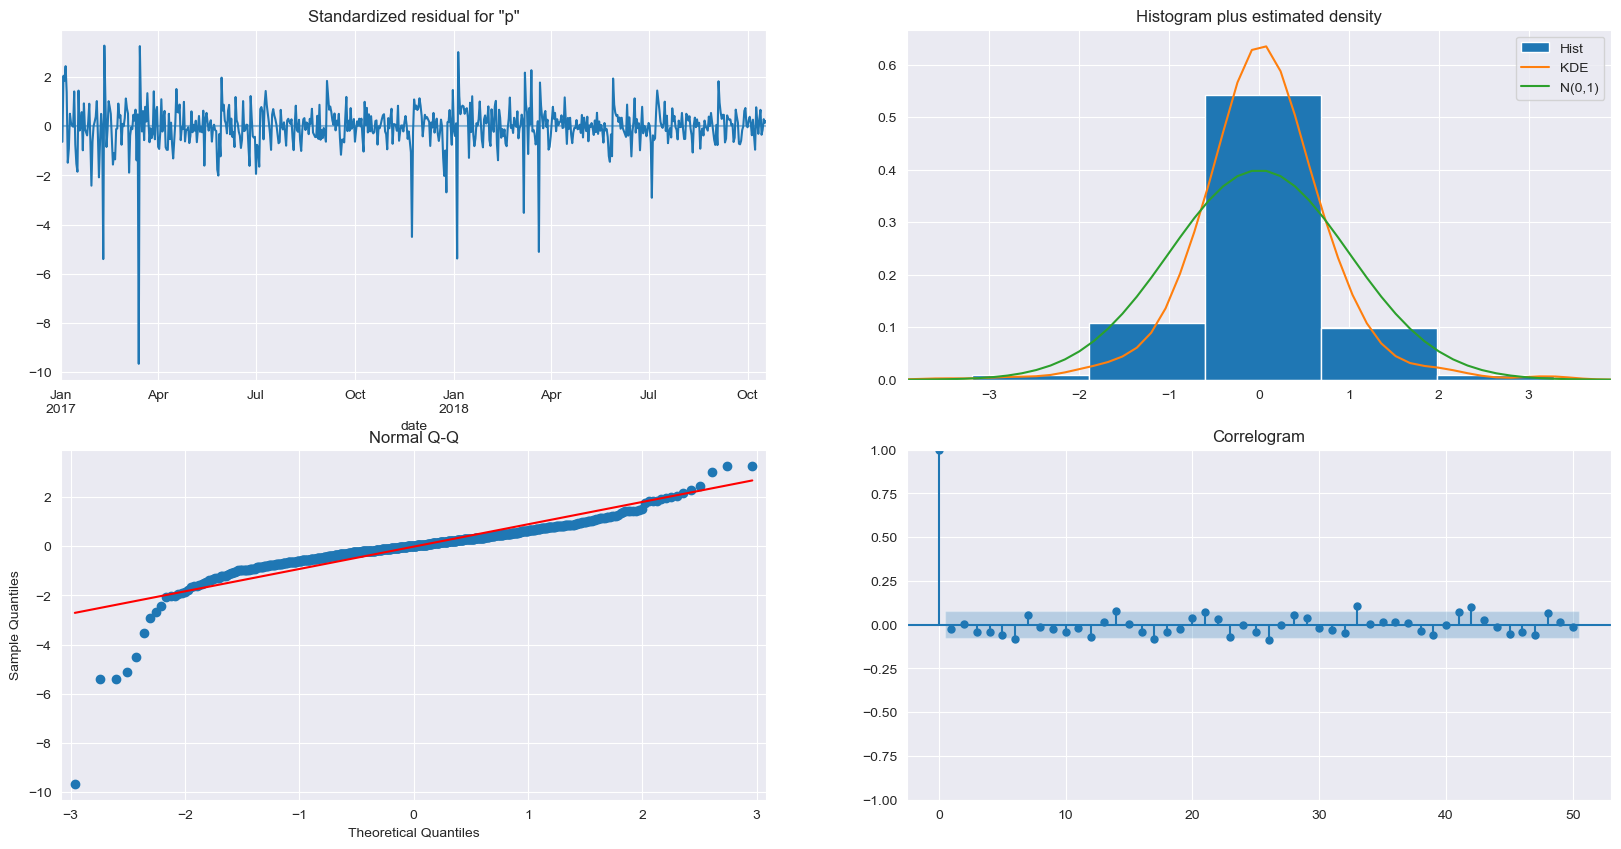

In [375]:
model = SARIMAX(
    df_train_lag365['pickup_count'],
    order=(5, 1, 0),
    seasonal_order=(2, 0, [1], 7),
    exog=df_train_lag365["pickup_count_lag_365"]
)

results = model.fit()

results.plot_diagnostics(
    lags=50,
    figsize=(20, 10)
)
plt.show()

Most of the ACF residuals fall within the confidence bands, suggesting no significant remaining autocorrelation. The normal Q-Q plot follows a roughly straight line, except for a few points that deviate substantially, indicating some extreme residuals.

### Final training and test prediction

In [376]:
import pandas as pd
import matplotlib.pyplot as plt

# final train set : train + validation
df_train_final = pd.concat([df_train, df_validation]).sort_index()
df_train_final_lag365 = pd.concat([df_train_lag365, df_validation_lag365]).sort_index()


# Model 1: SARIMAX with temp, sndp and day
history_weather, rmse_mean_weather, rmse_std_weather = evaluate_arimax_cv(
    df_train=df_train_final,
    df_validation=df_test,
    tscv=tscv,
    order=(5, 1, 0),
    seasonal_order=(2, 0, [1], 7),
    exog_variables=["temp", "sndp", "day"],
    forecast_steps=7
)

print("SARIMAX with weather exogenous features")
print("RMSE mean :", rmse_mean_weather)
print("RMSE std :", rmse_std_weather)


# Model 2 : SARIMAX with lag 365
history_lag365, rmse_mean_lag365, rmse_std_lag365 = evaluate_arimax_cv(
    df_train=df_train_final_lag365,
    df_validation=df_test_lag365,
    tscv=tscv,
    order=(5, 1, 0),
    seasonal_order=(2, 0, [1], 7),
    exog_variables=["pickup_count_lag_365"],
    forecast_steps=7
)

print("SARIMAX with lag365 exogenous variable")
print("RMSE mean :", rmse_mean_lag365)
print("RMSE std:", rmse_std_lag365)


SARIMAX with weather exogenous features
RMSE mean : 19067.622257179544
RMSE std : 14971.403430984232
SARIMAX with lag365 exogenous variable
RMSE mean : 17964.01736743766
RMSE std: 13930.89836217424


In [377]:

def plot_forecast_history(history, title, df):
    history = history.copy()
    history["date"] = pd.to_datetime(history["date"])
    history["forecast_origin"] = pd.to_datetime(history["forecast_origin"])

    first_date = history["date"].min()
    df = df.loc[first_date:].copy()

    plt.figure(figsize=(20, 8))

    sns.lineplot(
        x=df.index, y=df["pickup_count"],
        label="Real Value"
    )

    sns.lineplot(
        data=history, x="date", y="y_pred",
        label="Prediction", linestyle="--"
    )

    forecast_origins = sorted(set(history["forecast_origin"]))

    for i, origin in enumerate(forecast_origins):
        plt.axvline(
            x=origin,
            color="lightcoral",
            linestyle=":",
            alpha=0.5,
            label="Forecast origin" if i == 0 else None
        )

    plt.title(title)
    plt.xlabel("Date")
    plt.ylabel("Pickup count")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


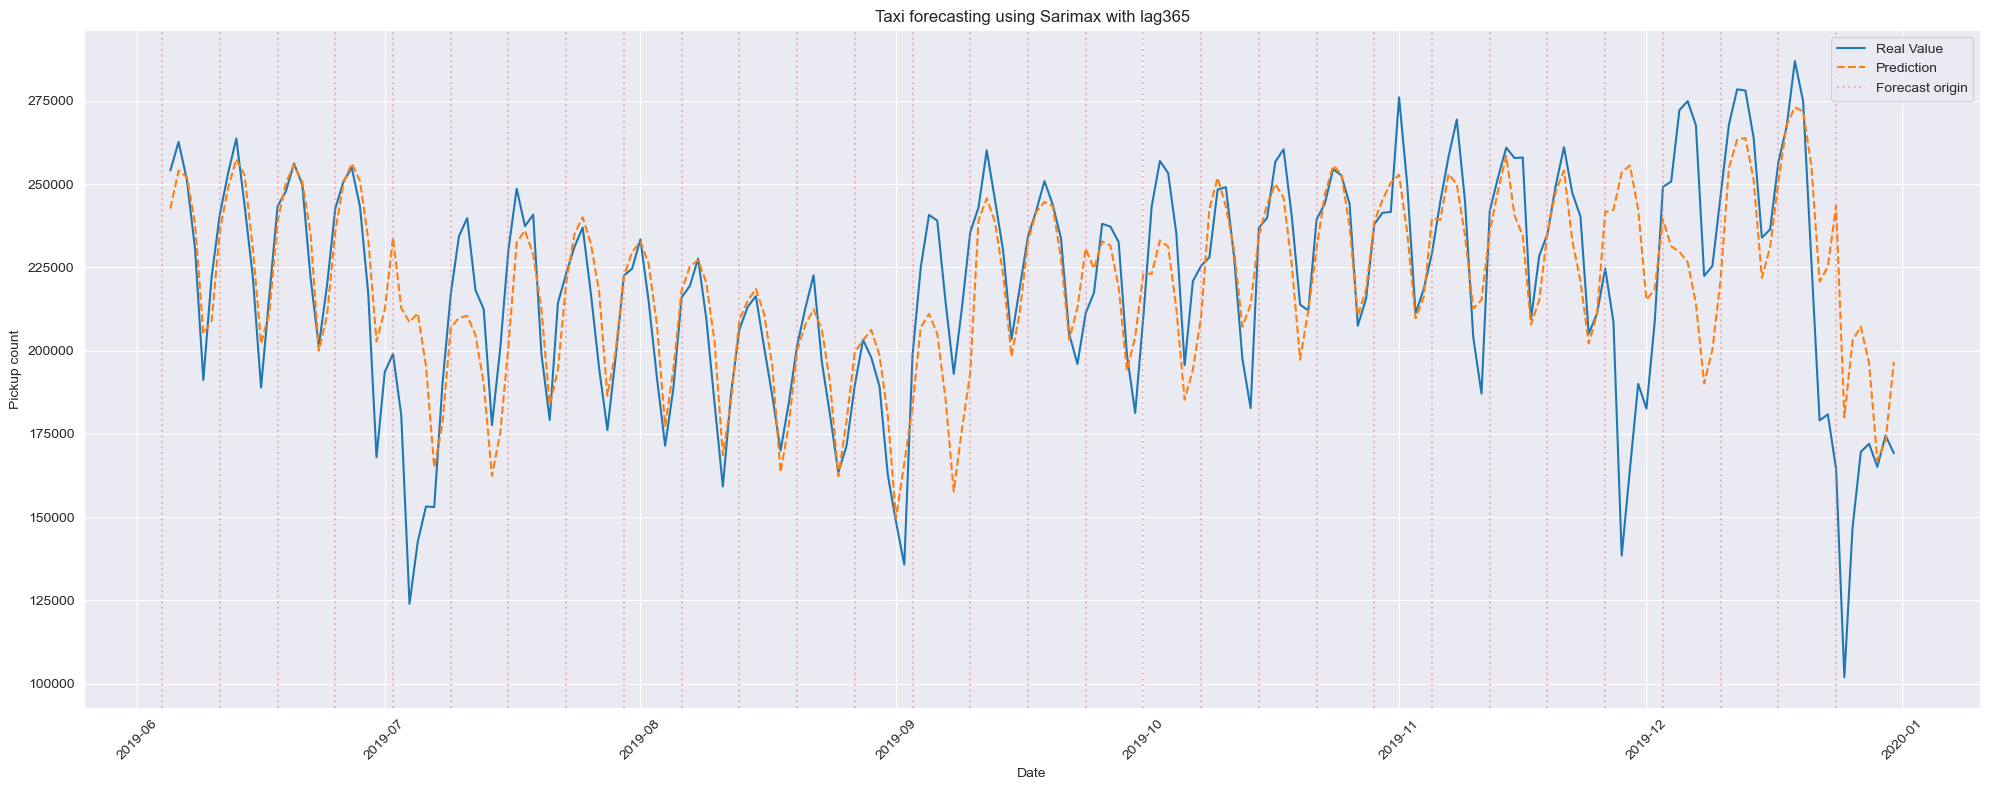

In [378]:
plot_forecast_history(
    history_lag365,
    "Taxi forecasting using Sarimax with lag365",
    df
)

The chart shows that the model captures the general trend of the time series reasonably well, but struggles to predict sudden increases or decreases in taxi demand.

Note that the chart combines predictions from all folds of the rolling-window evaluation rather than a single prediction over the entire test set. For each fold, the model forecasts the next 7 days. The red dotted lines indicate the forecast origins, corresponding to the last dates used for training before each prediction window.

### Conclusion

The results on the test set confirm that the model with the yearly lag performs better overall on unseen data.

In this notebook, we observed that the weather features did not improve our model's performance. We also experimented with several ways of incorporating seasonality through exogenous variables, including the day-of-year feature, its cyclical representation, and lag features. Ultimately, the yearly lag proved to be the most effective approach.

These results suggest that lag features are an effective way to capture seasonality, especially when the task requires the model to account for multiple seasonal patterns. This approach is particularly useful when using SARIMAX, as its standard seasonal component can only directly model one seasonal period at a time.